# Week 3 Day 5 – Daily Challenge
## Understanding the Essence of Machine Learning

This notebook is my summary of what machine learning is, why it matters for a data analyst, how the three main types of ML differ, and how I would move through feature selection, model selection and evaluation.


## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. Run the cells from top to bottom (Shift+Enter runs one cell).
3. The only code cell draws a flowchart of the ML process. No dataset is required.


## 1. What is machine learning?

Machine learning is a way for a computer to **find patterns in examples** and then use those patterns to make predictions or decisions about new cases. I do not write a long list of `if/else` rules by hand. Instead I give the algorithm data, I choose a type of model, and the model **learns the rules from the data**.

A simple picture is email spam filtering. I could try to write rules such as “if the subject contains the word lottery, mark it as spam”. Those rules break quickly, because spammers change their wording. With machine learning I show the model many emails that people already labelled as spam or not spam. The model learns which combinations of words and other signals are typical of spam, and then it can score a new email it has never seen.

The important idea for me as a beginner is this: the quality of the result depends on the **quality of the data**, on the **features** I give the model, and on how I **check** the model afterwards. A model is not magic. If I train it on biased or leaky data, it will learn the wrong thing.


## 2. Why machine learning matters for data analysts

As a data analyst I already describe what happened: I clean tables, I compute averages, and I draw charts. Machine learning extends that work from **describing the past** to **predicting what is likely to happen next** or **finding hidden groups** in the data.

This matters in my daily work for several reasons:

- I can turn a clean dataset into a practical tool, for example a score that estimates the chance a loan will not be repaid, or the chance a customer will leave.
- I still need the analyst skills I am learning now. If I pick the wrong features, ignore missing values, or leak the target into the inputs, the model will look good and then fail in real life.
- I must be able to explain the result to other people. A bank, a hospital or a manager will ask why the model made a decision. Understanding metrics and feature choice helps me answer that.
- Not every question needs machine learning. Sometimes a simple table or a chart is enough. Knowing the basics helps me decide when a model is worth the extra work.


## 3. Industry examples

Here are four places where machine learning is already used, written in plain language:

1. **Banking and credit.** A bank uses past loans to estimate whether a new applicant is likely to default. The model does not replace the credit officer, but it can rank applications and highlight the risky ones. This is the same idea as the loan exercises I did today.

2. **Healthcare.** Hospitals use models to help flag a disease on a medical image or to estimate the risk that a patient will be readmitted. A person still makes the final medical decision, because a missed diagnosis can be very serious.

3. **Retail and marketing.** Online shops recommend products based on what similar customers bought or viewed. The shop can also estimate which customers are about to stop buying, and then send a useful offer instead of a random email.

4. **Transport and logistics.** Delivery companies forecast demand in each area and estimate arrival times. Ride-hailing apps estimate how long I will wait for a car. These predictions help the company put drivers or vans in the right place.

In every example the pattern is the same: there is historical data, there is something useful to predict or to group, and someone has to check that the model is accurate enough and fair enough to use.


## 4. The three types of machine learning

### Supervised learning
In supervised learning, every training example already has the **correct answer** (the label). The model learns the link between the input features and that label, then predicts the label for new rows.

- If the label is a category, such as spam / not spam or default / no default, the task is **classification**.
- If the label is a number, such as a house price or tomorrow’s temperature, the task is **regression**.

Example: I train a model on old loan files where I already know whether each loan was approved or defaulted. Then I use the model on a new applicant.

### Unsupervised learning
In unsupervised learning, the data has **no ready-made label**. The model looks for structure, such as groups of similar rows or unusual points.

The most common technique I will meet first is **clustering**, for example K-Means. Another unsupervised idea is reducing many columns to a few summary dimensions, so a chart becomes readable.

Example: I group a library of books by similarity of titles and descriptions, without being given the genre of every book in advance.

### Reinforcement learning
In reinforcement learning, an **agent** learns by taking actions in an environment and receiving a **reward** or a penalty. There is no fixed table of “this row → this label”. The agent tries, gets feedback, and slowly improves its strategy.

Example: a robot learns to walk through a maze. It gets a reward when it reaches the exit and a small penalty for every extra step, so it is encouraged to find a shorter path.

These three types answer different questions. Supervised learning answers “What label or number should I predict?” Unsupervised learning answers “What groups or patterns are in this data?” Reinforcement learning answers “What action should I take next to get a better result over time?”


## 5. Three important stages: feature selection, model selection and evaluation

Even when the type of learning is clear, I still have to make good choices in this order.

### Feature selection
Features are the input columns the model is allowed to use. I keep features that help explain the target, and I drop columns that are identifiers, duplicates, leaks of the future answer, or sensitive attributes I should not use. In the loan dataset, `Credit_History` was very informative, while `Loan_ID` was only a name for the row and `Gender` was both weak and sensitive. Good feature selection often matters more than picking a fancy algorithm.

### Model selection
I choose a model that matches the problem. For a yes/no outcome I start with a simple classifier such as logistic regression, because I can explain it. Then I can compare it with a stronger model, such as a random forest. For a number I would choose a regression model. For grouping without labels I would choose a clustering method. I prefer to start simple: if a basic model already works well, I understand the problem better and I have a baseline to beat.

### Evaluation
I must measure the model on data it did not use while training, otherwise I only know that it memorised the training rows. I split the data (and I stratify the split when the classes are imbalanced), and I use cross-validation on the training set. I also pick metrics that match the goal. Accuracy is a good start, but it can hide mistakes when one class is rare. For loan risk or disease detection I also look at precision, recall, F1-score, the confusion matrix and ROC-AUC. If the scores are not good enough, I go back: I may change features, try another model, or adjust the decision threshold. I do not touch the final test set until the end, so the last number stays honest.


## 6. Flowchart of the process

The chart below is the path I would follow on a typical supervised project. Evaluation can send me back to feature selection or model selection if the result is not good enough.

```mermaid
flowchart TD
    A[Collect and clean the data] --> B[Feature selection]
    B --> C[Model selection]
    C --> D[Train the model]
    D --> E[Evaluation]
    E -->|scores are not good enough| B
    E -->|scores are good enough| F[Use the model and keep monitoring it]
```


I also draw the same process with matplotlib, so I still see the chart after I run the notebook even if mermaid is not rendered.


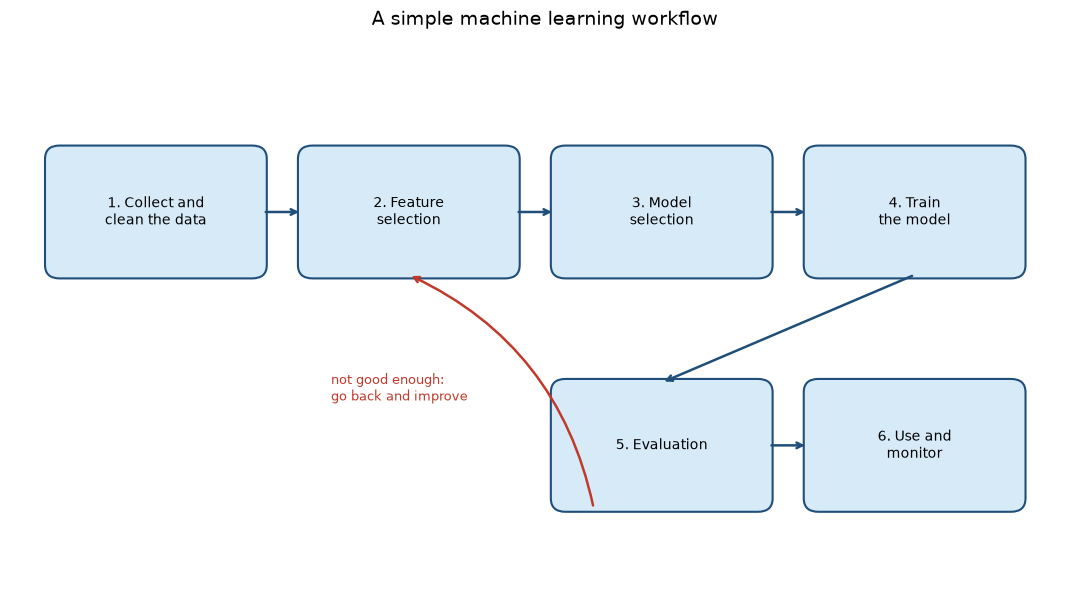

In [1]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 11)
ax.set_ylim(0, 6)
ax.axis("off")
ax.set_title("A simple machine learning workflow", fontsize=14, pad=12)

# boxes: (x, y, text)
boxes = [
    (0.4, 3.4, "1. Collect and\nclean the data"),
    (3.0, 3.4, "2. Feature\nselection"),
    (5.6, 3.4, "3. Model\nselection"),
    (8.2, 3.4, "4. Train\nthe model"),
    (5.6, 0.8, "5. Evaluation"),
    (8.2, 0.8, "6. Use and\nmonitor"),
]

for x, y, text in boxes:
    box = FancyBboxPatch(
        (x, y), 2.2, 1.4,
        boxstyle="round,pad=0.04,rounding_size=0.15",
        linewidth=1.5,
        edgecolor="#1f4e79",
        facecolor="#d6eaf8",
    )
    ax.add_patch(box)
    ax.text(x + 1.1, y + 0.7, text, ha="center", va="center", fontsize=10)

# forward arrows along the top row
arrow_style = dict(arrowstyle="->", color="#1f4e79", lw=1.8)
for x0 in [2.6, 5.2, 7.8]:
    ax.annotate("", xy=(x0 + 0.4, 4.1), xytext=(x0, 4.1), arrowprops=arrow_style)

# down from train to evaluation
ax.annotate("", xy=(6.7, 2.2), xytext=(9.3, 3.4), arrowprops=arrow_style)
# evaluation to use
ax.annotate("", xy=(8.2, 1.5), xytext=(7.8, 1.5), arrowprops=arrow_style)
# loop back from evaluation to feature selection
ax.annotate(
    "",
    xy=(4.1, 3.4),
    xytext=(6.0, 0.8),
    arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.8,
                    connectionstyle="arc3,rad=0.25"),
)
ax.text(3.3, 2.0, "not good enough:\ngo back and improve",
        color="#c0392b", fontsize=9)

plt.tight_layout()
plt.show()


## Short recap

Machine learning lets a computer learn patterns from examples instead of following only hand-written rules. For a data analyst it is the step from describing a table to making a careful prediction or finding groups. I will usually choose between supervised learning (labelled answers), unsupervised learning (no labels, look for structure) and reinforcement learning (learn from rewards). Whatever the type, I still need to select honest features, pick a model that fits the question, and evaluate it with metrics that match the real cost of mistakes.
